In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler

In [141]:
df = pd.read_csv("data/Concrete_Data.csv")

In [142]:
print("The shape of the data: ",df.shape)
print("Total numbers of missing data: ",df.isnull().sum().sum())
print("Total number of duplicated rows: ",df.duplicated().sum())
#print("Total duplicated rows: ",df[df.duplicated(keep = False)])

The shape of the data:  (1030, 9)
Total numbers of missing data:  0
Total number of duplicated rows:  25


In [143]:
df_clean = df.drop_duplicates().copy()
df_clean = df_clean.reset_index(drop=True)
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Duplicates remaining:", df_clean.duplicated().sum())

Original dataset: (1030, 9)
Cleaned dataset: (1005, 9)
Duplicates remaining: 0


In [144]:
statistics = df_clean.describe().T.round(3)
print(statistics)

                                                     count     mean      std  \
Cement (component 1)(kg in a m^3 mixture)           1005.0  278.631  104.344   
Blast Furnace Slag (component 2)(kg in a m^3 mi...  1005.0   72.043   86.171   
Fly Ash (component 3)(kg in a m^3 mixture)          1005.0   55.536   64.208   
Water  (component 4)(kg in a m^3 mixture)           1005.0  182.075   21.339   
Superplasticizer (component 5)(kg in a m^3 mixt...  1005.0    6.033    5.920   
Coarse Aggregate  (component 6)(kg in a m^3 mix...  1005.0  974.377   77.580   
Fine Aggregate (component 7)(kg in a m^3 mixture)   1005.0  772.688   80.340   
Age (day)                                           1005.0   45.857   63.735   
Concrete compressive strength(MPa, megapascals)     1005.0   35.250   16.285   

                                                       min     25%    50%  \
Cement (component 1)(kg in a m^3 mixture)           102.00  190.70  265.0   
Blast Furnace Slag (component 2)(kg in a m^3 

In [145]:
variance = df_clean.var()
print("Variance of each column:")
print(variance.round(2))

Variance of each column:
Cement (component 1)(kg in a m^3 mixture)                10887.72
Blast Furnace Slag (component 2)(kg in a m^3 mixture)     7425.41
Fly Ash (component 3)(kg in a m^3 mixture)                4122.66
Water  (component 4)(kg in a m^3 mixture)                  455.37
Superplasticizer (component 5)(kg in a m^3 mixture)         35.05
Coarse Aggregate  (component 6)(kg in a m^3 mixture)      6018.60
Fine Aggregate (component 7)(kg in a m^3 mixture)         6454.59
Age (day)                                                 4062.11
Concrete compressive strength(MPa, megapascals)            265.20
dtype: float64


In [146]:
skewness = df_clean.skew()
print("Skewness of each column:")
print(skewness.round(2))

Skewness of each column:
Cement (component 1)(kg in a m^3 mixture)                0.56
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0.86
Fly Ash (component 3)(kg in a m^3 mixture)               0.50
Water  (component 4)(kg in a m^3 mixture)                0.03
Superplasticizer (component 5)(kg in a m^3 mixture)      0.98
Coarse Aggregate  (component 6)(kg in a m^3 mixture)    -0.07
Fine Aggregate (component 7)(kg in a m^3 mixture)       -0.25
Age (day)                                                3.25
Concrete compressive strength(MPa, megapascals)          0.40
dtype: float64


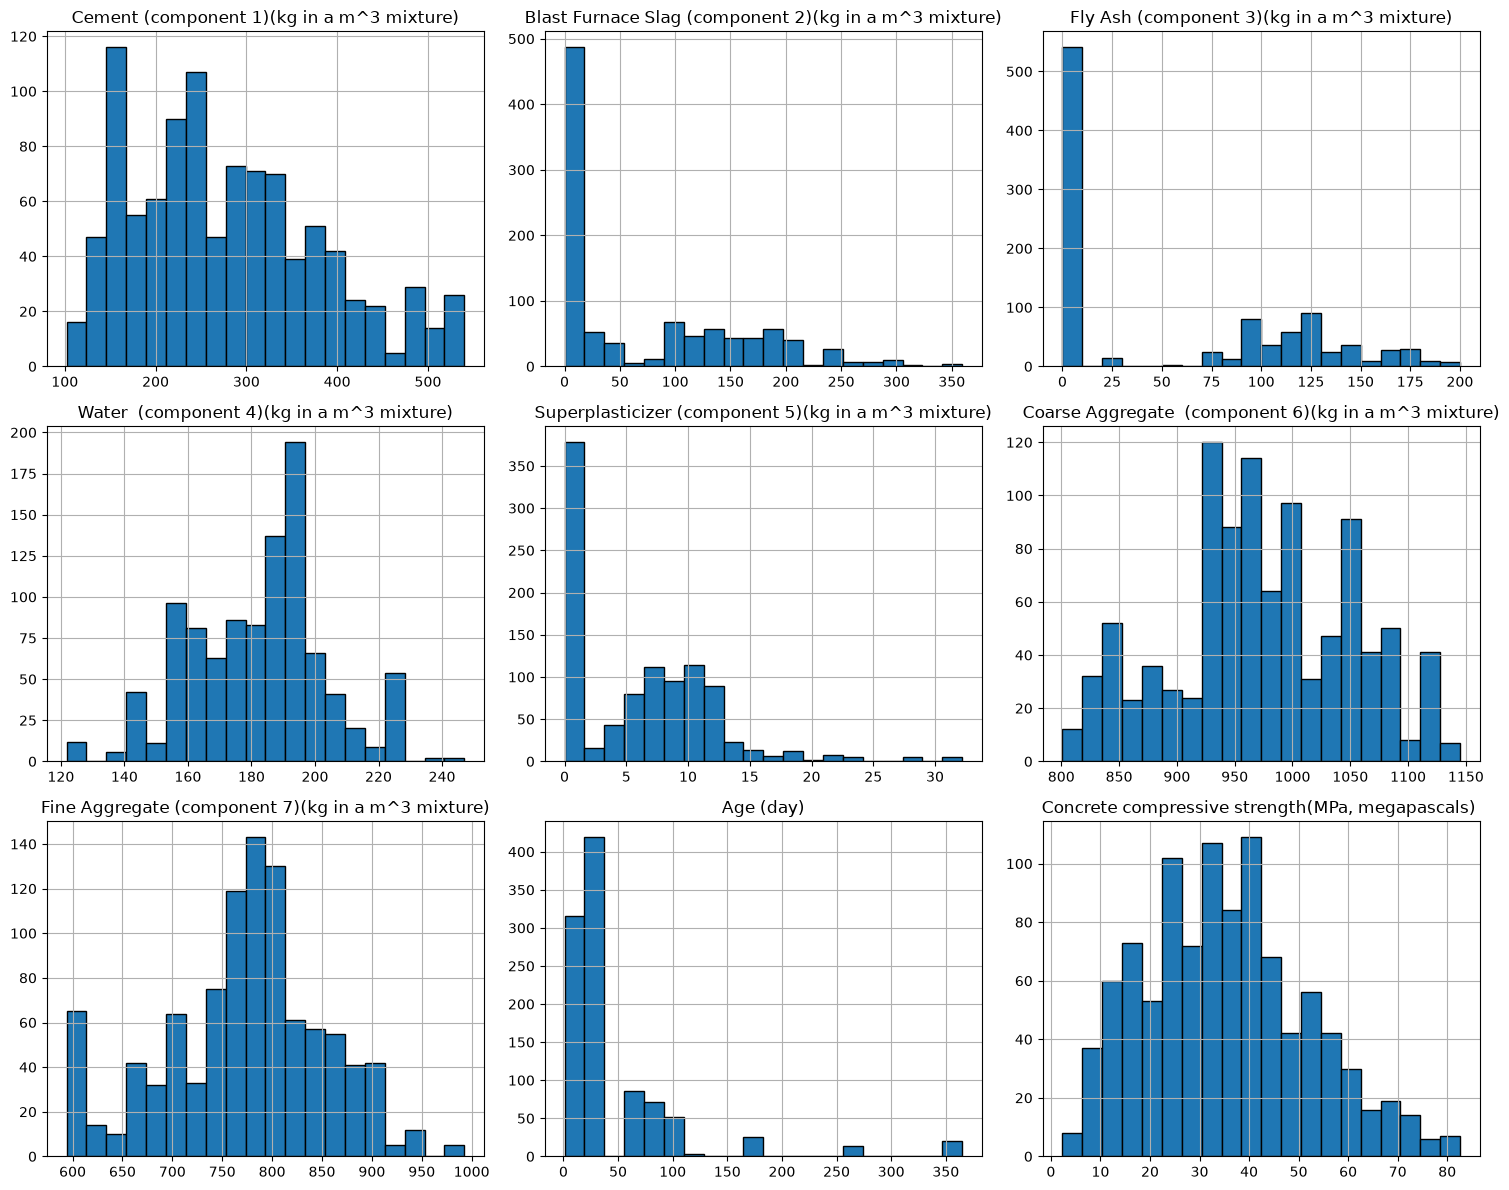

In [147]:
# this is for single column
# plt.figure(figsize=(4, 2))
# plt.hist(df_clean["Concrete compressive strength(MPa, megapascals) "],
#          bins=20,
#          edgecolor="black")
# plt.xlabel("Compressive Strength (MPa)")
# plt.ylabel("Frequency")
# plt.title("Distribution of Concrete Compressive Strength")
# plt.show()

df_clean.hist(figsize=(15, 12), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

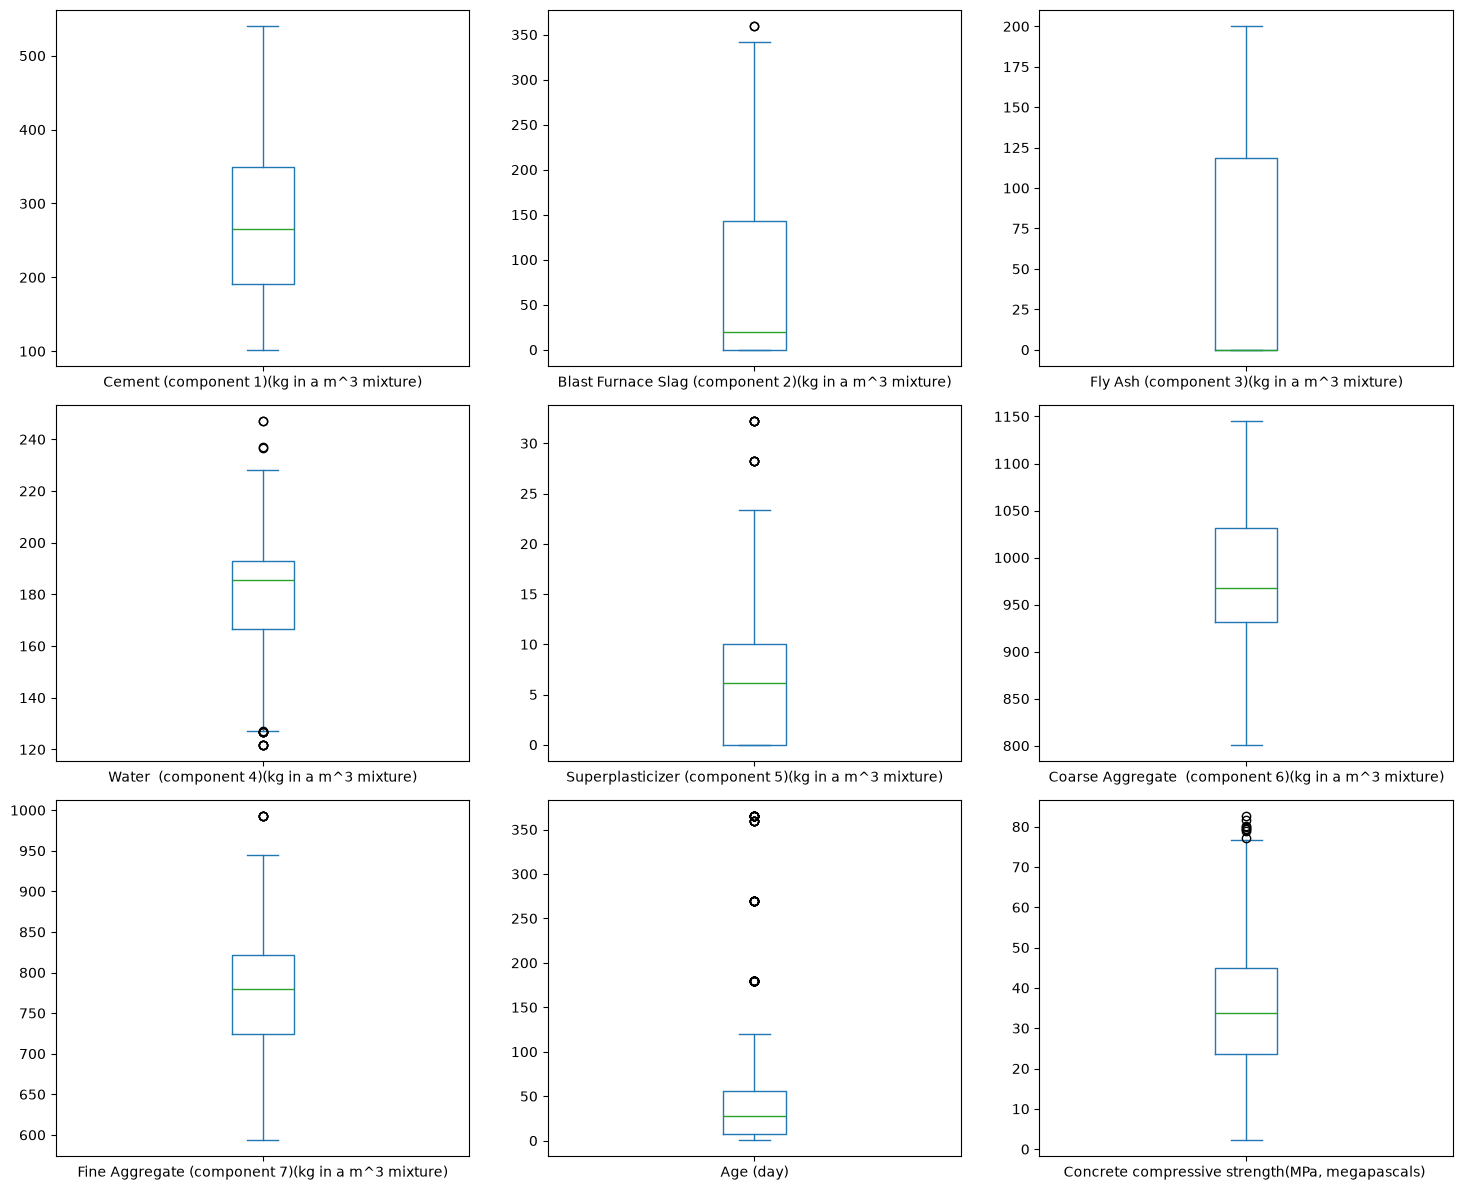

In [148]:
df_clean.plot(
    kind="box",
    subplots=True,
    layout=(3, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)
plt.tight_layout()
plt.show()

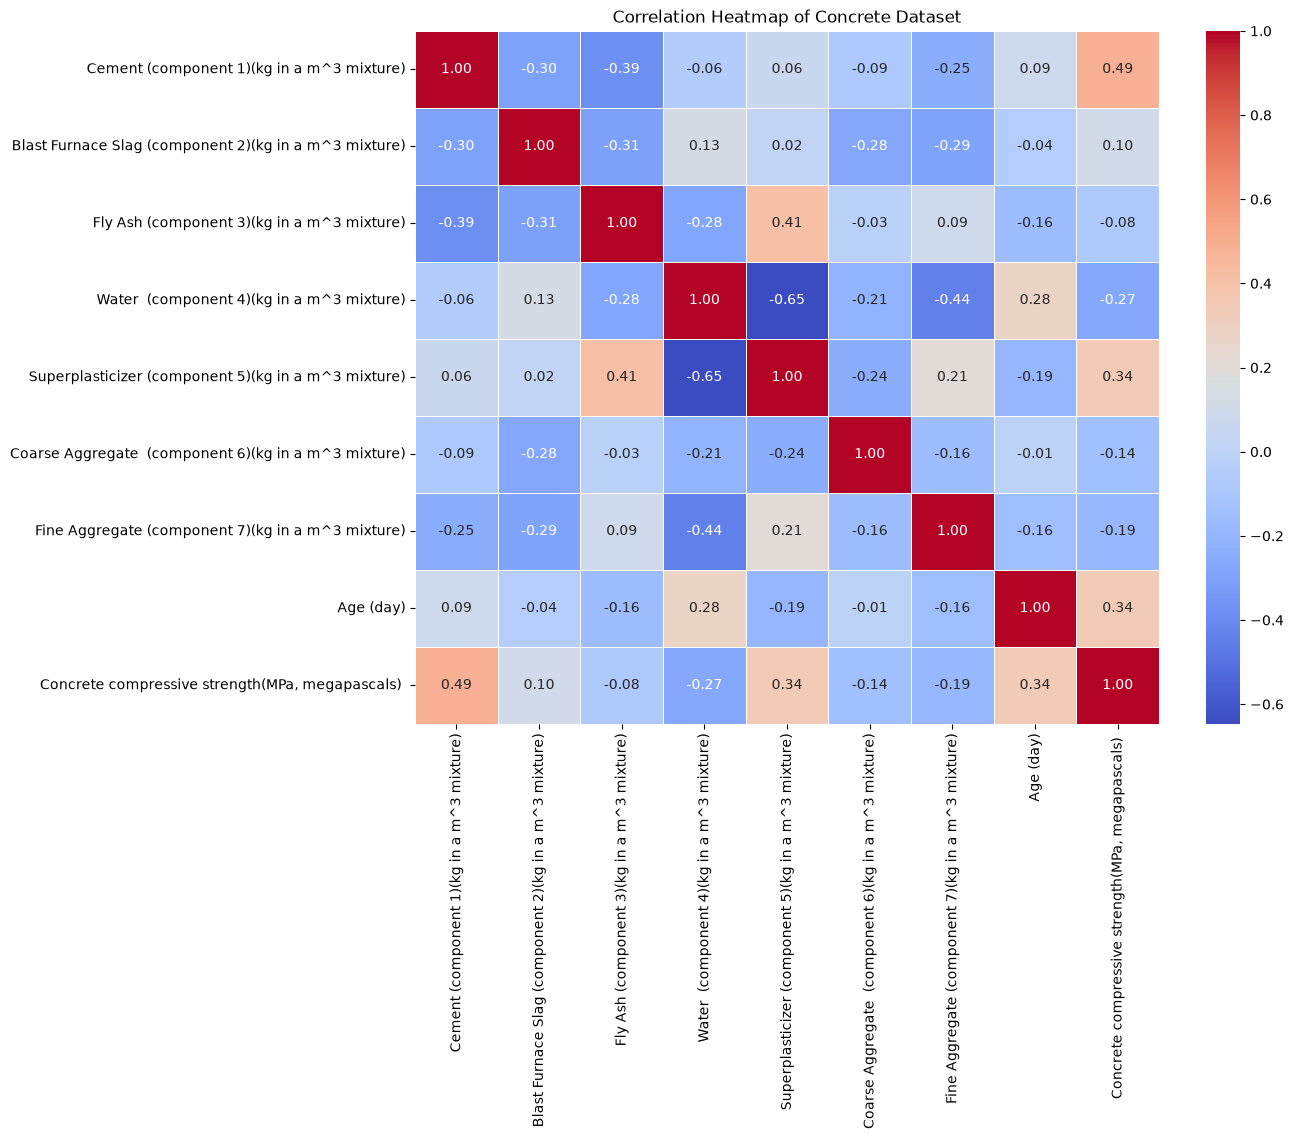

In [149]:
correlation_matrix = df_clean.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Concrete Dataset")
plt.show()

In [150]:
strength_correlation = correlation_matrix[
    "Concrete compressive strength(MPa, megapascals) "
]
print(strength_correlation.sort_values(ascending=False))

Concrete compressive strength(MPa, megapascals)          1.000000
Cement (component 1)(kg in a m^3 mixture)                0.488283
Superplasticizer (component 5)(kg in a m^3 mixture)      0.344209
Age (day)                                                0.337367
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0.103374
Fly Ash (component 3)(kg in a m^3 mixture)              -0.080648
Coarse Aggregate  (component 6)(kg in a m^3 mixture)    -0.144717
Fine Aggregate (component 7)(kg in a m^3 mixture)       -0.186448
Water  (component 4)(kg in a m^3 mixture)               -0.269624
Name: Concrete compressive strength(MPa, megapascals) , dtype: float64


In [151]:
# Features and Target

target = "Concrete compressive strength(MPa, megapascals) "
X = df_clean.drop(columns=[target])
y = df_clean[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())
print("\nFirst five target values:")
print(y.head())

Features shape: (1005, 8)
Target shape: (1005,)

Feature columns:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)']

First five target values:
0    79.99
1    61.89
2    40.27
3    41.05
4    44.30
Name: Concrete compressive strength(MPa, megapascals) , dtype: float64


In [152]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (804, 8)
Testing features: (201, 8)
Training target: (804,)
Testing target: (201,)


In [153]:
baseline_value = y_train.mean()
print("Mean compressive strength:", baseline_value)

Mean compressive strength: 35.066977611940295


In [154]:
# General prediction
y_pred_baseline = [baseline_value] * len(y_test)
print("First five predictions:", y_pred_baseline[:5])
print("Number of predictions:", len(y_pred_baseline))

First five predictions: [np.float64(35.066977611940295), np.float64(35.066977611940295), np.float64(35.066977611940295), np.float64(35.066977611940295), np.float64(35.066977611940295)]
Number of predictions: 201


In [155]:
baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)

print("Baseline Model Performance")
print("--------------------------")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)

Baseline Model Performance
--------------------------
MAE: 13.971914865968664
RMSE: 17.296409546308738
R2 Score: -0.0028187174165523743


In [156]:
# Inspecting
print("Training data:")
print(X_train.head())
print("\nTraining matrix shape:")
print(X_train.shape)
print("\nTraining target:")
print(y_train.head())
print(type(X_train))
print(type(y_train))

Training data:
     Cement (component 1)(kg in a m^3 mixture)  \
78                                       531.3   
29                                       475.0   
280                                      277.1   
507                                      436.0   
652                                      166.8   

     Blast Furnace Slag (component 2)(kg in a m^3 mixture)  \
78                                                 0.0       
29                                                 0.0       
280                                                0.0       
507                                                0.0       
652                                              250.2       

     Fly Ash (component 3)(kg in a m^3 mixture)  \
78                                          0.0   
29                                          0.0   
280                                        97.4   
507                                         0.0   
652                                         0.0   

    

In [157]:
# Manual NumPy Linear Regression Implementation
# Converting pandas DataFrames to NumPy arrays
X_array = X_train.to_numpy()
y_array = y_train.to_numpy()

# Inspecting the converted arrays
print("X array shape:", X_array.shape)
print("y array shape:", y_array.shape)
print("\nFirst row of X:")
print(X_array[0])
print("\nFirst value of y:")
print(y_array[0])
print()

# Creating intercept column for the design matrix
intercept = np.ones((X_array.shape[0], 1))
X_design = np.hstack((intercept, X_array))

print("Intercept shape:", intercept.shape)
print("Design matrix shape:", X_design.shape)
print("\nFirst row of design matrix:")
print(X_design[0])

X array shape: (804, 8)
y array shape: (804,)

First row of X:
[531.3   0.    0.  141.8  28.2 852.1 893.7   3. ]

First value of y:
41.3

Intercept shape: (804, 1)
Design matrix shape: (804, 9)

First row of design matrix:
[  1.  531.3   0.    0.  141.8  28.2 852.1 893.7   3. ]


In [158]:
# Calculating coefficients using NumPy
coefficients, residuals, rank, singular_values = np.linalg.lstsq(X_design, y_array, rcond=None)
print("Regression coefficients:")
print(np.round(coefficients, 5))
print("\nNumber of coefficients:")
print(len(coefficients))
print("\nRank:",rank)

Regression coefficients:
[-2.338935e+01  1.166700e-01  9.807000e-02  8.458000e-02 -1.313900e-01
  3.314800e-01  1.552000e-02  2.065000e-02  1.106400e-01]

Number of coefficients:
9

Rank: 9


In [159]:
# Prediction calculation
y_pred_train = X_design @ coefficients
print("First five actual values:")
print(y_array[:5])

print("\nFirst five predicted values:")
print(y_pred_train[:5])

print("\nNumber of predictions:")
print(len(y_pred_train))

First five actual values:
[41.3  38.6  23.14 23.85 15.75]

First five predicted values:
[61.32467975 29.576892   33.51697817 29.80704456 24.08830604]

Number of predictions:
804


In [160]:
# Preparing the testing data
X_test_array = X_test.to_numpy()
test_intercept = np.ones((X_test_array.shape[0], 1))
X_test_design = np.hstack((test_intercept, X_test_array))
y_pred_test = X_test_design @ coefficients

# Inspecting the predictions
print("First five actual test values:")
print(y_test.to_numpy()[:5])

print("\nFirst five predicted test values:")
print(y_pred_test[:5])

print("\nNumber of test predictions:")
print(len(y_pred_test))

First five actual test values:
[19.01 24.29 26.32 34.57 44.13]

First five predicted test values:
[23.46019162 16.70304272 22.45208992 37.39624296 42.88500822]

Number of test predictions:
201


In [161]:
numpy_mae = mean_absolute_error(y_test, y_pred_test)

numpy_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_test)
)

numpy_r2 = r2_score(y_test, y_pred_test)


print("NumPy Linear Regression Performance")
print("-----------------------------------")
print("MAE:", numpy_mae)
print("RMSE:", numpy_rmse)
print("R2 Score:", numpy_r2)

NumPy Linear Regression Performance
-----------------------------------
MAE: 8.895256221464198
RMSE: 11.19132021034614
R2 Score: 0.5801703029028775


In [162]:
# Comparison table between baseline and NumPy model
comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "NumPy Linear Regression"],
    "MAE": [baseline_mae, numpy_mae],
    "RMSE": [baseline_rmse, numpy_rmse],
    "R2 Score": [baseline_r2, numpy_r2]
})

print(comparison.round(3))

                     Model     MAE    RMSE  R2 Score
0            Mean Baseline  13.972  17.296    -0.003
1  NumPy Linear Regression   8.895  11.191     0.580


In [163]:
# Linear Regression using scikit-learn
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_sklearn = linear_model.predict(X_test)

sklearn_mae = mean_absolute_error(y_test, y_pred_sklearn)
sklearn_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_sklearn)
)
sklearn_r2 = r2_score(y_test, y_pred_sklearn)

print("Scikit-learn Linear Regression Performance")
print("------------------------------------------")
print("MAE:", sklearn_mae)
print("RMSE:", sklearn_rmse)
print("R2 Score:", sklearn_r2)

Scikit-learn Linear Regression Performance
------------------------------------------
MAE: 8.895256221464194
RMSE: 11.191320210346136
R2 Score: 0.5801703029028777


In [164]:
# Intercept and coefficients from scikit-learn model
print("Intercept:")
print(linear_model.intercept_)
print("\nCoefficients:")
print(linear_model.coef_)

coefficient_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": linear_model.coef_
})
print(coefficient_table)

Intercept:
-23.38934728534784

Coefficients:
[ 0.11666665  0.09806639  0.08458468 -0.13139102  0.33147986  0.01552205
  0.02064931  0.11064223]
                                             Feature  Coefficient
0          Cement (component 1)(kg in a m^3 mixture)     0.116667
1  Blast Furnace Slag (component 2)(kg in a m^3 m...     0.098066
2         Fly Ash (component 3)(kg in a m^3 mixture)     0.084585
3          Water  (component 4)(kg in a m^3 mixture)    -0.131391
4  Superplasticizer (component 5)(kg in a m^3 mix...     0.331480
5  Coarse Aggregate  (component 6)(kg in a m^3 mi...     0.015522
6  Fine Aggregate (component 7)(kg in a m^3 mixture)     0.020649
7                                          Age (day)     0.110642


In [165]:
# Residuals
residuals = y_test - y_pred_sklearn

print("First five residuals:")
print(residuals.head())

print("\nMean residual:")
print(residuals.mean())

print("\nStandard deviation of residuals:")
print(residuals.std())

First five residuals:
926   -4.450192
630    7.586957
682    3.867910
514   -2.826243
365    1.244992
Name: Concrete compressive strength(MPa, megapascals) , dtype: float64

Mean residual:
0.6992459585208208

Standard deviation of residuals:
11.197342839070979


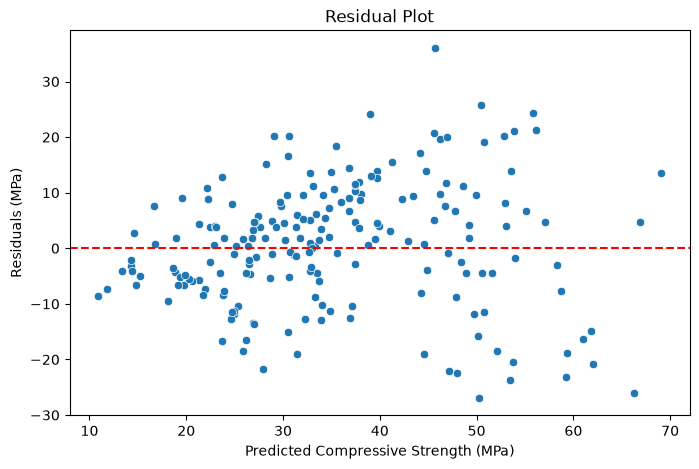

In [166]:
# Residual plot
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=y_pred_sklearn,
    y=residuals
)
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)
plt.xlabel("Predicted Compressive Strength (MPa)")
plt.ylabel("Residuals (MPa)")
plt.title("Residual Plot")
plt.show()

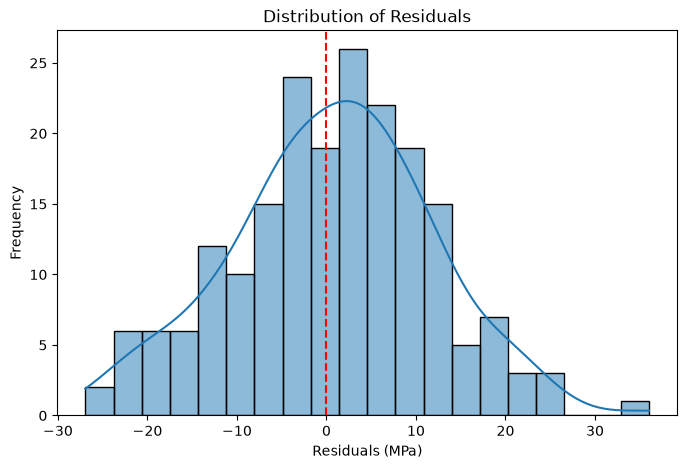

In [167]:
# Residual distribution plot
plt.figure(figsize=(8, 5))
sns.histplot(
    residuals,
    bins=20,
    kde=True
)
plt.axvline(
    x=0,
    color="red",
    linestyle="--"
)
plt.xlabel("Residuals (MPa)")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

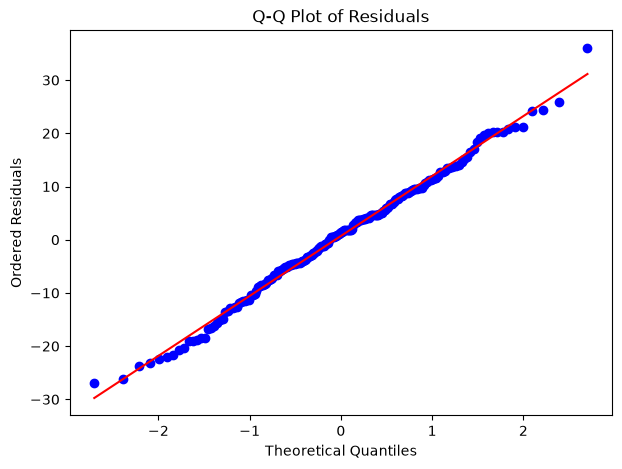

In [168]:
# Q-Q plot to compare the distribution of residuals to a normal distribution
plt.figure(figsize=(7, 5))
stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)
plt.title("Q-Q Plot of Residuals")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Ordered Residuals")
plt.show()

|Assumption|	Current assessment|
|---|---|
|Linearity|	Possible concern|
|Independence	|Not checked|
|Homoscedasticity|	Possible concern|
Normality	|Reasonably satisfied|
|Multicollinearity|	Needs VIF investigation|

In [169]:
# AI suggested code for VIF calculation
# Some general guidelines:
# VIF	    Interpretation
# 1	        No linear multicollinearity with other features
# 1–5	    Usually acceptable
# 5–10	    Potentially concerning
# Above 10	Often considered serious
# These are guidelines, not absolute rules.

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X_train.copy()

vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print(vif_data.sort_values("VIF", ascending=False))

                                             Feature       VIF
1  Blast Furnace Slag (component 2)(kg in a m^3 m...  7.199801
0          Cement (component 1)(kg in a m^3 mixture)  7.111387
6  Fine Aggregate (component 7)(kg in a m^3 mixture)  7.072842
3          Water  (component 4)(kg in a m^3 mixture)  6.944043
2         Fly Ash (component 3)(kg in a m^3 mixture)  6.050103
5  Coarse Aggregate  (component 6)(kg in a m^3 mi...  4.985777
4  Superplasticizer (component 5)(kg in a m^3 mix...  2.913190
7                                          Age (day)  1.134450


Several mixture ingredients have VIF values between 6 and 7.2. This suggests moderate-to-high multicollinearity.
It means some of the input features can be explained partly by combinations of other input features.
This can make individual regression coefficients less stable and harder to interpret.
However, multicollinearity does not automatically mean that the model's predictions are poor.

In [170]:
# Feature scaling, Ridge and Lasso regression

# Stadardization of features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Original training data:")
print(X_train.mean().round(2))
print("\nScaled training data - means:")
print(X_train_scaled.mean(axis=0).round(4))
print("\nScaled training data - standard deviations:")
print(X_train_scaled.std(axis=0).round(4))

Original training data:
Cement (component 1)(kg in a m^3 mixture)                278.18
Blast Furnace Slag (component 2)(kg in a m^3 mixture)     72.07
Fly Ash (component 3)(kg in a m^3 mixture)                56.33
Water  (component 4)(kg in a m^3 mixture)                182.11
Superplasticizer (component 5)(kg in a m^3 mixture)        6.08
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     972.60
Fine Aggregate (component 7)(kg in a m^3 mixture)        773.42
Age (day)                                                 45.31
dtype: float64

Scaled training data - means:
[-0. -0.  0. -0.  0. -0. -0. -0.]

Scaled training data - standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [171]:
# Ridge Regression
from sklearn.linear_model import Ridge
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_model.predict(X_test_scaled)

ridge_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_r2 = r2_score(y_test, y_pred_ridge)
print("Ridge Regression Performance")
print("-----------------------------")
print("MAE:", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)

Ridge Regression Performance
-----------------------------
MAE: 8.897597667613852
RMSE: 11.193353390704226
R2 Score: 0.5800177441313179


In [172]:
# Lasso Regression
from sklearn.linear_model import Lasso
lasso_model = Lasso(alpha=0.1, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_model.predict(X_test_scaled)

lasso_mae = mean_absolute_error(y_test, y_pred_lasso)
lasso_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
lasso_r2 = r2_score(y_test, y_pred_lasso)
print("Lasso Regression Performance")
print("-----------------------------")
print("MAE:", lasso_mae)
print("RMSE:", lasso_rmse)
print("R2 Score:", lasso_r2)

Lasso Regression Performance
-----------------------------
MAE: 8.922551108037146
RMSE: 11.229477527216947
R2 Score: 0.5773025653673826


In [173]:
lasso_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lasso_model.coef_
})
print(lasso_coefficients)

print("\nNumber of features eliminated:",
      np.sum(lasso_model.coef_ == 0))

                                             Feature  Coefficient
0          Cement (component 1)(kg in a m^3 mixture)    10.328639
1  Blast Furnace Slag (component 2)(kg in a m^3 m...     6.614416
2         Fly Ash (component 3)(kg in a m^3 mixture)     3.828315
3          Water  (component 4)(kg in a m^3 mixture)    -4.012453
4  Superplasticizer (component 5)(kg in a m^3 mix...     1.933465
5  Coarse Aggregate  (component 6)(kg in a m^3 mi...    -0.000000
6  Fine Aggregate (component 7)(kg in a m^3 mixture)     0.000000
7                                          Age (day)     6.657433

Number of features eliminated: 2


In [174]:
# Choosing best alpha using cross-validation

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Creating a range of alpha values to test
alphas = np.logspace(-3, 3, 13)
print(alphas)

# Creating Ridge pipeline
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Performing grid search
ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"ridge__alpha": alphas},
    cv=5,
    scoring="neg_mean_squared_error"
)
ridge_grid.fit(X_train, y_train)

# Displaying the best alpha and corresponding RMSE
print("Best Ridge Alpha:", ridge_grid.best_params_["ridge__alpha"])
print("Best Cross-Validation RMSE:",
      np.sqrt(-ridge_grid.best_score_))

[1.00000000e-03 3.16227766e-03 1.00000000e-02 3.16227766e-02
 1.00000000e-01 3.16227766e-01 1.00000000e+00 3.16227766e+00
 1.00000000e+01 3.16227766e+01 1.00000000e+02 3.16227766e+02
 1.00000000e+03]
Best Ridge Alpha: 1.0
Best Cross-Validation RMSE: 10.175846387351307


In [175]:
# Creating Lasso pipeline
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=10000))
])

# Performing grid search
lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"lasso__alpha": alphas},
    cv=5,
    scoring="neg_mean_squared_error"
)
lasso_grid.fit(X_train, y_train)

# Displaying the best alpha and corresponding RMSE
print("Best Lasso Alpha:", lasso_grid.best_params_["lasso__alpha"])
print("Best Cross-Validation RMSE:",
      np.sqrt(-lasso_grid.best_score_))

Best Lasso Alpha: 0.0031622776601683794
Best Cross-Validation RMSE: 10.176631811395135


In [176]:
# Training the tuned models
# Best Ridge model
best_ridge = ridge_grid.best_estimator_
# Best Lasso model
best_lasso = lasso_grid.best_estimator_

# Predictions
y_pred_ridge_tuned = best_ridge.predict(X_test)
y_pred_lasso_tuned = best_lasso.predict(X_test)

# Ridge metrics
ridge_tuned_mae = mean_absolute_error(y_test, y_pred_ridge_tuned)
ridge_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge_tuned))
ridge_tuned_r2 = r2_score(y_test, y_pred_ridge_tuned)

# Lasso metrics
lasso_tuned_mae = mean_absolute_error(y_test, y_pred_lasso_tuned)
lasso_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso_tuned))
lasso_tuned_r2 = r2_score(y_test, y_pred_lasso_tuned)

In [177]:
print("Tuned Ridge Regression")
print("----------------------")
print("MAE:", ridge_tuned_mae)
print("RMSE:", ridge_tuned_rmse)
print("R2:", ridge_tuned_r2)

print("\nTuned Lasso Regression")
print("----------------------")
print("MAE:", lasso_tuned_mae)
print("RMSE:", lasso_tuned_rmse)
print("R2:", lasso_tuned_r2)

Tuned Ridge Regression
----------------------
MAE: 8.897597667613852
RMSE: 11.193353390704226
R2: 0.5800177441313179

Tuned Lasso Regression
----------------------
MAE: 8.895925751582967
RMSE: 11.191829689469529
R2: 0.5801320769687165


In [178]:
# Comparison of all models

results = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "NumPy Linear Regression",
        "Scikit-learn Linear Regression",
        "Ridge (Initial)",
        "Lasso (Initial)",
        "Ridge (Tuned)",
        "Lasso (Tuned)"
    ],

    "MAE": [
        baseline_mae,
        mean_absolute_error(y_test, y_pred_test),
        mean_absolute_error(y_test, y_pred_sklearn),
        ridge_mae,
        lasso_mae,
        ridge_tuned_mae,
        lasso_tuned_mae
    ],

    "RMSE": [
        baseline_rmse,
        np.sqrt(mean_squared_error(y_test, y_pred_test)),
        np.sqrt(mean_squared_error(y_test, y_pred_sklearn)),
        ridge_rmse,
        lasso_rmse,
        ridge_tuned_rmse,
        lasso_tuned_rmse
    ],

    "R2": [
        baseline_r2,
        r2_score(y_test, y_pred_test),
        r2_score(y_test, y_pred_sklearn),
        ridge_r2,
        lasso_r2,
        ridge_tuned_r2,
        lasso_tuned_r2
    ]
})

print(results.round(4))

                            Model      MAE     RMSE      R2
0                   Mean Baseline  13.9719  17.2964 -0.0028
1         NumPy Linear Regression   8.8953  11.1913  0.5802
2  Scikit-learn Linear Regression   8.8953  11.1913  0.5802
3                 Ridge (Initial)   8.8976  11.1934  0.5800
4                 Lasso (Initial)   8.9226  11.2295  0.5773
5                   Ridge (Tuned)   8.8976  11.1934  0.5800
6                   Lasso (Tuned)   8.8959  11.1918  0.5801


In [179]:
# Training performance
train_mae = mean_absolute_error(y_train, y_pred_train)
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
train_r2 = r2_score(y_train, y_pred_train)

# Testing performance
test_mae = mean_absolute_error(y_test, y_pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
test_r2 = r2_score(y_test, y_pred_test)

# We are using the NumPy Linear Regression model because it is equivalent to our Scikit-learn Linear Regression model.

print("Training Performance")
print("--------------------")
print("MAE:", train_mae)
print("RMSE:", train_rmse)
print("R2:", train_r2)

print("\nTesting Performance")
print("-------------------")
print("MAE:", test_mae)
print("RMSE:", test_rmse)
print("R2:", test_r2)

Training Performance
--------------------
MAE: 7.959910074856394
RMSE: 10.001794718033251
R2: 0.6098668648171734

Testing Performance
-------------------
MAE: 8.895256221464198
RMSE: 11.19132021034614
R2: 0.5801703029028775


### Interpretation: No strong overfitting observed
Training and testing performance are reasonably close. The linear model generalizes reasonably well, although it does not capture all the variation in concrete compressive strength.

                                             Feature  Coefficient  \
0          Cement (component 1)(kg in a m^3 mixture)    12.037786   
1  Blast Furnace Slag (component 2)(kg in a m^3 m...     8.354392   
7                                          Age (day)     6.885964   
2         Fly Ash (component 3)(kg in a m^3 mixture)     5.368344   
3          Water  (component 4)(kg in a m^3 mixture)    -2.890643   
4  Superplasticizer (component 5)(kg in a m^3 mix...     1.962748   
6  Fine Aggregate (component 7)(kg in a m^3 mixture)     1.590657   
5  Coarse Aggregate  (component 6)(kg in a m^3 mi...     1.135729   

   Absolute Coefficient  
0             12.037786  
1              8.354392  
7              6.885964  
2              5.368344  
3              2.890643  
4              1.962748  
6              1.590657  
5              1.135729  


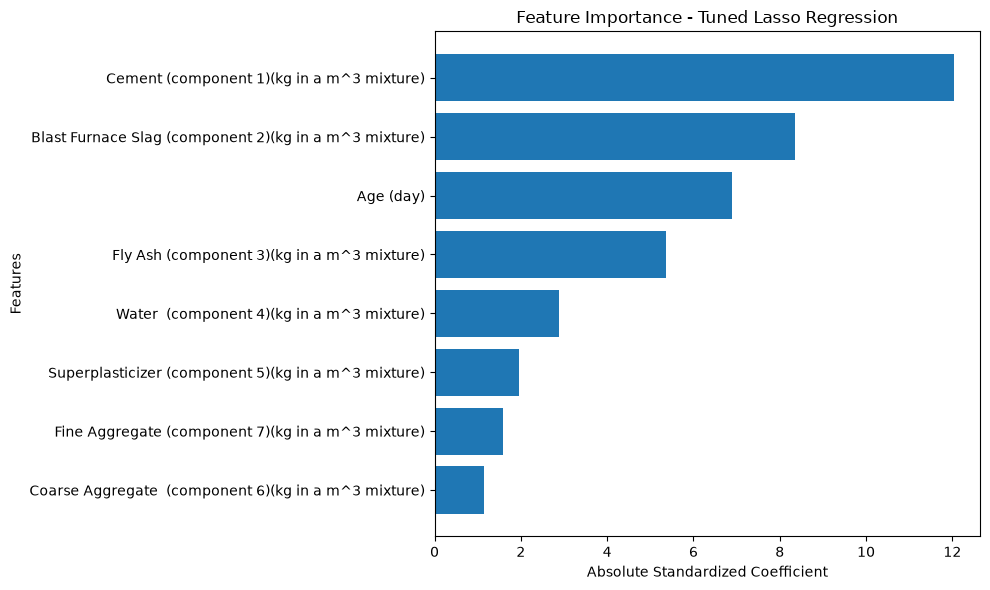

In [180]:
# Feature importance

lasso_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": best_lasso.named_steps["lasso"].coef_
})
lasso_coefficients["Absolute Coefficient"] = (
    lasso_coefficients["Coefficient"].abs()
)
lasso_coefficients = lasso_coefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)
print(lasso_coefficients)

plt.figure(figsize=(10, 6))
plt.barh(
    lasso_coefficients["Feature"],
    lasso_coefficients["Absolute Coefficient"]
)
plt.xlabel("Absolute Standardized Coefficient")
plt.ylabel("Features")
plt.title("Feature Importance - Tuned Lasso Regression")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Feature Importance

1. Cement has the strongest coefficient.
Its coefficient is approximately +12.04.
In our standardized model, increasing cement by one standard deviation is associated with an estimated increase of approximately 12.04 MPa in compressive strength, assuming other features remain constant.

2. Blast Furnace Slag also has a strong positive coefficient.
Its coefficient is +8.35, suggesting a substantial positive association in this fitted model.

3. Age has a strong positive coefficient.
Concrete generally gains strength as hydration progresses. Our model captures this positive relationship.

4. Water has a negative coefficient.
Its coefficient is approximately -2.89.
This is consistent with an important concrete engineering principle: increasing the water-to-cement ratio generally reduces concrete strength, although the actual relationship is more complicated than this model represents.

5. Aggregate variables have relatively small coefficients.
Fine and coarse aggregates have smaller coefficients in this particular model. This does not mean aggregates are unimportant in concrete engineering. Their effects may be nonlinear or shared with other mixture variables.

## Model Limitations

### 1. Limited dataset size
After removing duplicates, we had 1,005 observations.
This is a relatively small dataset for machine learning. A larger and more diverse dataset could improve generalization.

### 2. Limited input features
Our model uses only eight input variables:
- Cement
- Blast Furnace Slag
- Fly Ash
- Water
- Superplasticizer
- Coarse Aggregate
- Fine Aggregate
- Age
Other factors, such as curing temperature, humidity, cement type, admixture composition and environmental conditions, are not included.

### 3. Linear model limitations
Ordinary Linear Regression assumes a linear relationship between the input features and the target.
However, concrete strength development is a complex process involving hydration, water-to-cement ratio, material interactions and curing conditions.
A linear model cannot fully capture all these relationships.

### 4. Multicollinearity
Our VIF analysis showed that several ingredient variables have moderately high VIF values.
This can make individual regression coefficients unstable and difficult to interpret.

### 5. Outliers and experimental variation
Some observations had unusually high or low values.
These could represent legitimate experimental results, but they can also influence regression coefficients and predictions.

### 6. Limited generalization
Our model was trained and evaluated using observations from the same dataset.
Its performance on concrete mixtures from different laboratories, regions, material sources or production conditions has not been established.

## Conclusion

In this project, machine learning techniques were applied to predict the compressive strength of concrete using eight mixture-related input variables. The dataset initially contained 1,030 observations. After removing 25 duplicate records, 1,005 observations were retained for analysis.

Exploratory data analysis was performed to investigate feature distributions, statistical properties, outliers and correlations. Cement content showed the strongest positive correlation with compressive strength, while water content showed a negative correlation.

A mean baseline model was first established, followed by Linear Regression implemented using both NumPy and Scikit-learn. Ridge and Lasso regression were subsequently implemented to investigate the effects of regularization. Five-fold cross-validation was used to select suitable regularization parameters.

Among the evaluated models, ordinary Linear Regression achieved the best test performance, with an MAE of 8.895 MPa, an RMSE of 11.191 MPa and an R² score of 0.580. The tuned Ridge and Lasso models produced nearly identical results, indicating that regularization did not provide a meaningful improvement in predictive performance for this dataset.

The standardized coefficients of the tuned Lasso model identified cement, blast furnace slag and concrete age as the strongest positive predictors, while water content showed a negative relationship with compressive strength.

The comparison between training and testing performance indicated no strong evidence of overfitting. However, the moderate R² score suggests that a considerable proportion of the variation in concrete strength remains unexplained.

Overall, the project demonstrates the application of data preprocessing, exploratory analysis, linear regression, regularization, cross-validation and model evaluation to an engineering prediction problem. Future improvements could involve nonlinear regression techniques, ensemble learning methods, additional material properties and a larger, more diverse experimental dataset.